# Example: KMT-2023-BLG-0466 — two caustic grazes and a single data point

This is one of a series of example notebooks that run lenscape's map pipeline, with its default settings, on
published planetary events. Together they show both how well the method works and where it reaches its limits.
`example_kb200202` is the first of them.

**The event.** KMT-2023-BLG-0466 (Han et al. 2026, *Four Cold Super-Jupiters Revealed by Extended and Complex
Microlensing Signals*, arXiv:2601.13450) peaked in April 2023 at a moderate magnification (*A* ≈ 6.5). All three KMTNet
telescopes observed it. After the peak the light curve shows two short anomalies, at HJD′ ≈ 10062.4 (*t*₁) and
10072.2 (*t*₂), where HJD′ = HJD − 2450000. The source passes outside a resonant caustic and grazes it twice. Many
points from all three sites cover *t*₂, but a **single KMTA point** covers *t*₁. Han et al. report a unique solution
with *s* = 1.078, *q* = 6.97 × 10⁻³ and *t*ₑ = 43.4 d (their Table 4). They note that the *t*₁ point first looked like
an outlier, and that it pins down the trajectory. Section 7 measures how much it does.

**What this notebook does.**

1. It loads the public photometry of the three KMTNet sites (909 points).
2. It computes the map on the lattice of Han et al.'s Fig. 2 (24 × 52 points).
3. It densifies the map three times, to 2×, 4× and 8×.
4. It compares the four maps with each other and with the published map.
5. It zooms in on the central valley (Section 6).
6. It shows the light curves of the alternative solutions and the role of the *t*₁ point (Section 7).
7. It looks at what the maps get wrong (Section 8).

**Runtime.** The four maps took 19, 25, 64 and 222 minutes, and the three zoom maps of Section 6 another 48 minutes,
6.3 hours in total, on a 14-core Intel Core i5-13500 (20 threads). They are stored in `data/`, so the notebook runs in a few minutes by default (most of it in the fits of
Sections 6 to 8). Set `RECOMPUTE = True` to recompute the maps.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import minimize
import lenscape
from lenscape import figures

RECOMPUTE = False              # True: compute all maps again (6.3 h on a 20-thread desktop) instead of loading them
print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/kb230466_photometry.csv` holds the public pySIS difference-imaging photometry from the KMTNet event page: field
BLG34, *I* band, HJD′ 9940–10180, from KMTNet Chile (KMTC34), South Africa (KMTS34) and Australia (KMTA34). It has
one row per measurement:

| column | meaning |
|---|---|
| `set` | data set (`KMTC34`, `KMTS34`, `KMTA34`) |
| `t` | HJD − 2450000 |
| `flux` | pySIS difference flux Δflux (arbitrary zero point; in these files it *decreases* as the star brightens) |
| `flux_err` | its error, rescaled (see below) |

The error bars are rescaled with the usual error model (Yee et al. 2012): σ′ = *k* √(σ² + σ_min²) in magnitudes, with
σ_min = 0.010 as in Han et al. (Table 2), and one *k* per data set chosen so that the best fit has χ²/N = 1 for each
(*k* = 1.25, 1.50 and 2.18 for KMTC, KMTS and KMTA). Points more than 5σ off the best fit were removed. Han et al.
used their own re-reduction of the same images (*k* = 0.65, 0.98, 0.79), so their χ² values are not on the same scale
as ours (Section 5).

In [2]:
rows = np.genfromtxt("data/kb230466_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
SETS = ["KMTC34", "KMTS34", "KMTA34"]
# pySIS Delta_flux falls as the star brightens; flip the sign so that brighter is up. The fit does not care: the
# source and blend fluxes change sign, chi2 is identical.
data = lenscape.Data.from_sets({n: (rows["t"][rows["set"] == n], -rows["flux"][rows["set"] == n],
                                    rows["flux_err"][rows["set"] == n]) for n in SETS})
data

Data(909 points, t 9996.86 .. 10179.89, sets {'KMTC34': 446, 'KMTS34': 216, 'KMTA34': 247})

## 2. The best fit

A map needs one good model as its starting point, given as `(t0, u0, tE, log10 s, log10 q, alpha, log10 rho)`. This
one was fitted to these data from the published parameters (`lenscape.fit_full`). It agrees with Table 4 of Han et
al.:

| | *s* | *q* (10⁻³) | *t*ₑ (d) | ρ (10⁻³) | *t*₀ (HJD′) | \|*u*₀\| |
|---|---|---|---|---|---|---|
| Han et al. (2026) | 1.0779 ± 0.0037 | 6.97 ± 0.89 | 43.43 ± 1.68 | 1.20 ± 0.47 | 10058.15 ± 0.14 | 0.1505 ± 0.0082 |
| these data | 1.077 | 6.51 | 44.71 | 1.11 | 10058.08 | 0.1509 |

The trajectory angle α and the sign of *u*₀ are not compared because the two codes use different conventions.

The plot shows all three data sets on the flux scale of KMTC34. Each set is aligned with the source and blend fluxes
of the best fit (KMTS and KMTA have their own zero points and flux scales), so the models of other solutions in later
plots are drawn for KMTC34 only. The residual panels use each solution's own fluxes and are exact.

chi2 = 909.0 for 909 points;  s = 1.0770, q = 6.51e-3, tE = 44.71 d, rho = 1.11e-3


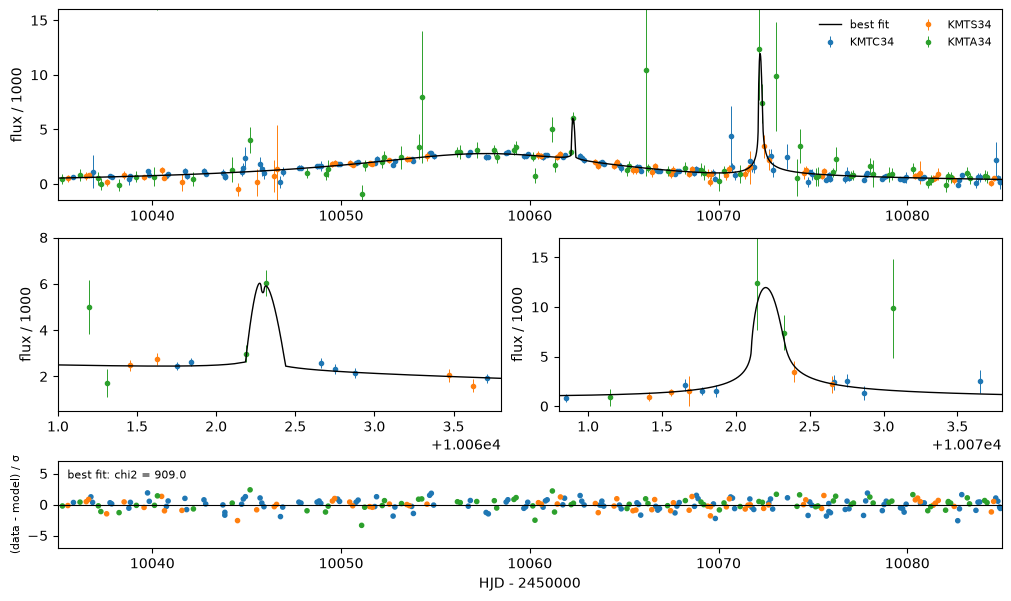

In [3]:
best = np.array([10058.08454912298, -0.15087246698530907, 44.712640602209056, 0.03222057343507832,
                 -2.1864127863588525, 3.5868766983817744, -2.9546647435821947])
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
chi2_best = lenscape.model.chi2(be, best, data)
print(f"chi2 = {chi2_best:.1f} for {len(data)} points;  s = {10 ** best[3]:.4f}, q = {10 ** best[4] * 1e3:.2f}e-3, "
      f"tE = {best[2]:.2f} d, rho = {10 ** best[6] * 1e3:.2f}e-3")


def plot_flux(sols, window=(10035, 10085), zooms=((10061.0, 10063.8), (10070.8, 10073.8)),
              ylims=((-1.5, 16), (0.5, 8), (-0.5, 17)), d=None):
    # data of all sets on the KMTC34 flux scale (aligned with the best fit), the KMTC34 model of each solution, two
    # zooms on the anomalies and one panel of normalised residuals per solution (each with its own fluxes); the
    # y ranges are fixed because a few KMTA points have huge error bars and some models have caustic spikes
    d = data if d is None else d
    styles = ["-", ":", "--", "-."]
    fs0, fb0 = lenscape.model.fluxes(lenscape.model.magnification(be, best, d), d)
    fig = plt.figure(figsize=(10, 4.8 + 1.1 * len(sols)), constrained_layout=True)
    gs = fig.add_gridspec(2 + len(sols), 2, height_ratios=[2.2, 2.0] + [1] * len(sols))
    top = fig.add_subplot(gs[0, :]); zax = [fig.add_subplot(gs[1, k]) for k in range(2)]
    for ax, (a, b), yl in zip([top] + zax, [window] + list(zooms), ylims):
        for k, name in enumerate(d.names):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            f = (d.f[m] - fb0[k]) / fs0[k] * fs0[0] + fb0[0]
            ax.errorbar(d.t[m], f / 1e3, d.e[m] * abs(fs0[0] / fs0[k]) / 1e3, fmt="o", ms=3, lw=0.7, color=f"C{k}",
                        label=name if ax is top else None, zorder=2)
        tt = np.linspace(a, b, 3000)
        for (name, p), ls in zip(sols.items(), styles):
            fs, fb = lenscape.model.fluxes(lenscape.model.magnification(be, p, d), d)
            Am = be.lc(lenscape.model.clamp(p)[0], tt)
            ax.plot(tt, (fs[0] * Am + fb[0]) / 1e3, ls, color="k", lw=1, label=name if ax is top else None, zorder=3)
        ax.set_xlim(a, b); ax.set_ylim(*yl); ax.set_ylabel("flux / 1000")
    top.legend(fontsize=8, frameon=False, ncol=2)
    for k, (name, p) in enumerate(sols.items()):
        ax = fig.add_subplot(gs[2 + k, :], sharex=top)
        r = lenscape.model.residuals(be, p, d)
        m = (d.t > window[0]) & (d.t < window[1])
        ax.scatter(d.t[m], r[m], s=9, c=[f"C{i}" for i in d.idx[m]]); ax.axhline(0, color="k", lw=0.8)
        ax.set_ylim(-7, 7); ax.set_ylabel("(data - model) / σ", fontsize=8)
        ax.text(0.01, 0.8, f"{name}: chi2 = {np.sum(r ** 2):.1f}", transform=ax.transAxes, fontsize=8)
    ax.set_xlabel("HJD - 2450000")
    return fig

plot_flux({"best fit": best});

The left zoom is *t*₁: the KMTA point at HJD′ 10062.31 lies far above the KMTC and KMTS points around it, and the best
fit passes through it with a spike of a few hours. The right zoom is *t*₂, covered by all three sites.

For later comparison, here is the **single-lens floor**: the χ² of the best point-lens model (with a finite source),
measured against the binary best fit. Points of a map with Δχ² near this value are no better than having no planet
at all.

In [4]:
def chi2_1l1s(x):
    A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]), 10 ** x[3], data.t, 0.0)
    fs, fb = lenscape.model.fluxes(A, data)
    return float((((data.f - fs[data.idx] * A - fb[data.idx]) / data.e) ** 2).sum())

chi2_single = min(minimize(chi2_1l1s, [best[0], u0, best[2], -3.0], method="Nelder-Mead",
                           options=dict(maxfev=4000, adaptive=True)).fun for u0 in (0.01, 0.03, 0.1, 0.3))
floor = chi2_single - chi2_best
print(f"single-lens floor: Delta chi2 = {floor:.0f}")

single-lens floor: Delta chi2 = 114


The floor is only about 114, against about 630 for KMT-2020-BLG-0202: the planet here changes the light curve only
during the two short grazes.

## 3. Stage 1: the lattice of the published map

These are the axes of Han et al.'s Fig. 2, measured from the figure, plus a margin of two points on each side. There
are 24 points in log *s* from −0.234 to +0.288 (step 0.0227) and 52 points in log *q* from −3.61 to −0.98 (step
0.0516). The steps are about half those of KMT-2020-BLG-0202 and still about 45 times wider than those of the
MOA-2022-BLG-091 map in `tutorial_first_map_research_note`. `lenscape.lattice` runs its five stages (seed grid, cell
fits, lattice-point fits, neighbour refinement, outlier recalculation); `06_maps` explains each. **Runtime: 19
minutes** (20 threads).

In [5]:
dls, dlq = 0.0227, 0.0516
logs1 = -0.2340 + dls * np.arange(24)
logq1 = -3.6075 + dlq * np.arange(52)
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")

def run_or_load(name, compute):
    if RECOMPUTE:
        m = compute()
        np.savez_compressed(f"data/kb230466_map_{name}.npz", **{k: m[k] for k in KEYS})
        return m
    return dict(np.load(f"data/kb230466_map_{name}.npz"))

map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best))
print(f"{map1['chi2'].shape} points, wall time {map1['wall'] / 60:.0f} min")

(24, 52) points, wall time 19 min


## 4. Stages 2 to 4: two, four and eight times the resolution

`lenscape.maps.densify` fits every point of a finer lattice from the nearest known solutions. It then refines the
map with the same neighbour and outlier stages as `lattice`. The 8× map starts from the 4× map alone: every 4× point
is also an 8× point and already holds the best solution the 1× and 2× maps found there. **Runtime: 25 minutes for 2×
(47 × 103 points), 64 minutes for 4× (93 × 205 points), 222 minutes for 8× (185 × 409 points).**

In [6]:
map2 = run_or_load("2x", lambda: lenscape.maps.densify(
    [map1], data, logs1[0] + dls / 2 * np.arange(47), logq1[0] + dlq / 2 * np.arange(103), best=best))
map4 = run_or_load("4x", lambda: lenscape.maps.densify(
    [map1, map2], data, logs1[0] + dls / 4 * np.arange(93), logq1[0] + dlq / 4 * np.arange(205), best=best))
# 8x from the 4x map alone: every 4x point already holds the best of the 1x and 2x solutions there
map8 = run_or_load("8x", lambda: lenscape.maps.densify(
    [map4], data, logs1[0] + dls / 8 * np.arange(185), logq1[0] + dlq / 8 * np.arange(409), best=best))
MAPS = [("1x", map1), ("2x", map2), ("4x", map4), ("8x", map8)]
ref = min(chi2_best, np.nanmin(map8["chi2"]))
for name, m in MAPS:
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"{name}: {m['chi2'].shape[0]:2d} x {m['chi2'].shape[1]:3d} points, wall time {m['wall'] / 60:2.0f} min, "
          f"minimum {m['chi2'][i, j] - chi2_best:+.2f} against the best fit at log s = {m['logs'][i]:.4f}, "
          f"log q = {m['logq'][j]:.3f}")

1x: 24 x  52 points, wall time 19 min, minimum +3.93 against the best fit at log s = 0.0384, log q = -2.008
2x: 47 x 103 points, wall time 25 min, minimum +3.62 against the best fit at log s = 0.0384, log q = -1.982
4x: 93 x 205 points, wall time 64 min, minimum -0.35 against the best fit at log s = 0.0327, log q = -2.150
8x: 185 x 409 points, wall time 222 min, minimum -0.35 against the best fit at log s = 0.0327, log q = -2.150


## 5. The four maps

All four maps are drawn against the same reference χ², the lower of the best fit and the 8× minimum, with a
logarithmic colour scale up to Δχ² = 100. The single-lens floor (≈ 114) is just above that, so everything at the top
of the scale is no better than a single lens.

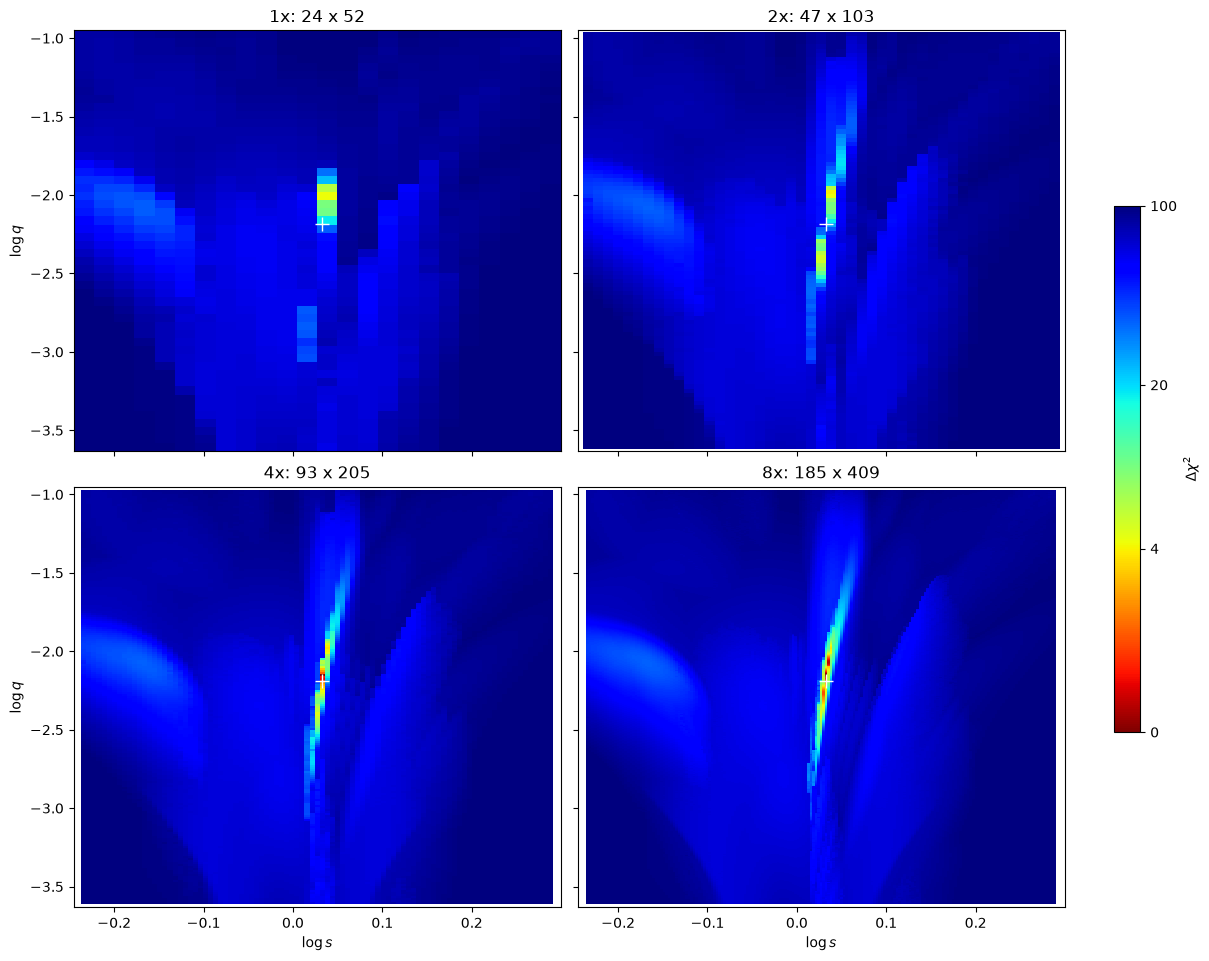

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(12, 9.5), constrained_layout=True, sharex=True, sharey=True)
for ax, (name, m) in zip(axs.flat, MAPS):
    figures.plot_map(m, ax=ax, vmax=100, chi2_ref=ref, colorbar=False)
    ax.plot(best[3], best[4], "w+", ms=10)
    ax.set_title(f"{name}: {m['chi2'].shape[0]} x {m['chi2'].shape[1]}")
for ax in axs[0]: ax.set_xlabel("")
for ax in axs[:, 1]: ax.set_ylabel("")
ticks = np.array([0, 4, 20, 100])                         # one colour bar for all four (same scale as plot_map's)
cb = fig.colorbar(axs[0, 0].images[0], ax=axs, shrink=0.6, ticks=np.log10(ticks + 1))
cb.set_ticklabels([str(t) for t in ticks]); cb.set_label(r"$\Delta\chi^2$");

All four maps have one minimum, at the resonant separation log *s* ≈ 0.03 (white cross: the best fit), inside a
narrow valley that runs almost vertically through the lattice, from log *s* ≈ 0.06 at log *q* = −1.5 to log *s* ≈ 0.02
at log *q* = −3. Two weaker arms lie to either
side: a close one at log *s* ≈ −0.2 and a wide one at log *s* ≈ 0.1.

The valley is narrower than one step of the 1× lattice. Its deepest part lies between two 1× columns, so the 1× and
2× minima are about 4 above the best fit. The 4× lattice has a point near the best fit, where it found a model
slightly better (by 0.35) than our stored best fit, and the 8× map has its minimum at the same point. In the 1× map
the valley is a broken line of separate patches; at 2× and 4× it is continuous but still ragged, at 8× it is smooth.
Section 8.1 measures this, and Section 6 zooms in.

**Comparison with the paper.** `data/kb230466_han2026_fig2.csv` holds the coloured cells of Han et al.'s Fig. 2, read
from the figure's vector graphics. Their bands are Δχ² ≤ *n* × (1, 4, 9, 16) with *n* = 4, white above 64. We draw
them next to our 8× map in the same bands, with no rescaling.

1x: of the 255 paper cells, same band 14 %, within one band 85 %, above 64 in our map 75 %
4x: of the 255 paper cells, same band 13 %, within one band 90 %, above 64 in our map 70 %
8x: of the 255 paper cells, same band 15 %, within one band 90 %, above 64 in our map 69 %


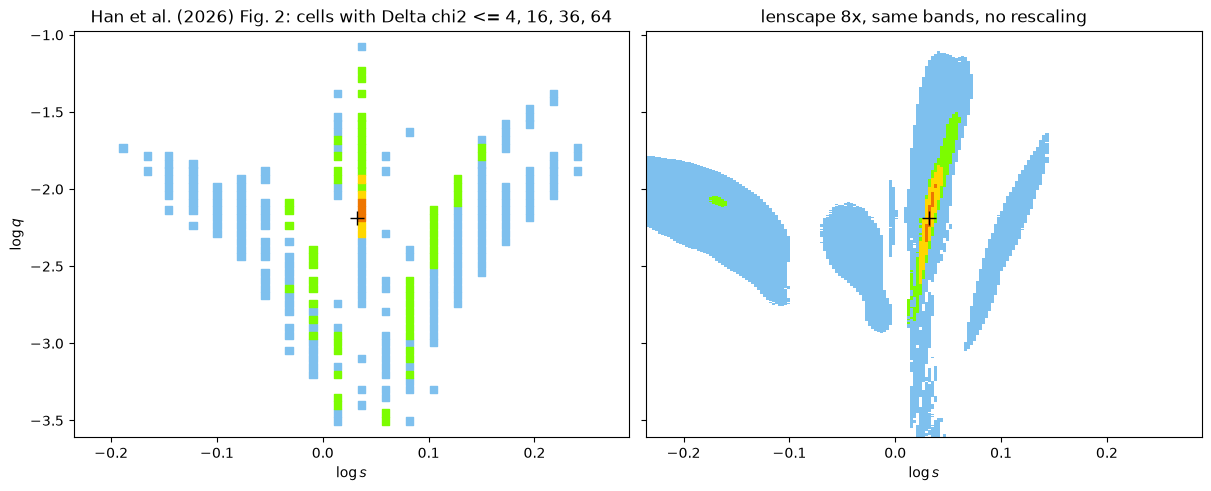

In [8]:
cells = np.genfromtxt("data/kb230466_han2026_fig2.csv", delimiter=",", names=True, skip_header=2)
edges = 4 * np.array([1, 4, 9, 16])
band_cmap = ListedColormap(["#ee7600", "gold", "lawngreen", "#7ec0ee", "white"])
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True, sharex=True, sharey=True)
o = np.argsort(-cells["band"])
axs[0].scatter(cells["log_s"][o], cells["log_q"][o], c=cells["band"][o] - 1, cmap=band_cmap, vmin=-0.5, vmax=4.5,
               marker="s", s=28)
axs[0].set_title("Han et al. (2026) Fig. 2: cells with Delta chi2 <= 4, 16, 36, 64")
band8 = np.searchsorted(edges, map8["chi2"] - ref)                       # 0..3 inside the bands, 4 above 64
axs[1].pcolormesh(map8["logs"], map8["logq"], band8.T, cmap=band_cmap, vmin=-0.5, vmax=4.5, shading="nearest")
axs[1].set_title("lenscape 8x, same bands, no rescaling")
for ax in axs:
    ax.plot(best[3], best[4], "k+", ms=10); ax.set_xlabel(r"$\log s$")
axs[0].set_ylabel(r"$\log q$")

# band of our maps at each paper cell (nearest lattice point)
for name, m in [("1x", map1), ("4x", map4), ("8x", map8)]:
    i = np.round((cells["log_s"] - m["logs"][0]) / (m["logs"][1] - m["logs"][0])).astype(int)
    j = np.round((cells["log_q"] - m["logq"][0]) / (m["logq"][1] - m["logq"][0])).astype(int)
    ours = np.searchsorted(edges, m["chi2"][i, j] - ref) + 1
    print(f"{name}: of the {len(cells)} paper cells, same band {100 * np.mean(ours == cells['band']):.0f} %, within one "
          f"band {100 * np.mean(abs(ours - cells['band']) <= 1):.0f} %, above 64 in our map {100 * np.mean(ours == 5):.0f} %")

The topology is the same: a central column with the minimum, a close arm and a wide arm, and the column continuing to
log *q* ≈ −3.5. The paper's arms are broader and their levels are lower than ours: most of the paper's cells (all ≤ 64)
lie above 64 in our map, though nearly all within one band. Its values are lower than ours by a factor between about
1 and 2. That is no sign of a missed solution: deep searches at four points of the column below log *q* = −2.7
reproduce our values (Section 8.2), and the two maps are computed from different reductions with different error
bars.

## 6. Zoom on the central valley

The valley around the minimum is very narrow in log *s*. Near the mass ratio of the minimum, only one point of the 8×
lattice lies within Δχ² < 4 of it, and the 8× map shows the valley as a row of separate columns. Rather than densify
the whole lattice again, we compute a **zoom**: a new lattice over the box 0.011 ≤ log *s* ≤ 0.050,
−2.70 ≤ log *q* ≤ −1.77, which contains every 8× point with Δχ² < 16.

* 50 × 50 points, started from the 8× map with `densify` (5 minutes);
* 99 × 99 points, started from the 50 × 50 zoom (11 minutes);
* 197 × 197 points, started from the 99 × 99 zoom (32 minutes).

The finest zoom has steps of 0.0002 dex in log *s* (14 times finer than the 8× map) and 0.0048 dex in log *q* (1.4 times
finer). All three are stored in `data/` like the other maps.

In [9]:
zls, zlq = 0.0008, 0.019
zlogs, zlogq = 0.0110 + zls * np.arange(50), -2.700 + zlq * np.arange(50)
zoom1 = run_or_load("zoom_1x", lambda: lenscape.maps.densify([map8], data, zlogs, zlogq, best=best))
zoom2 = run_or_load("zoom_2x", lambda: lenscape.maps.densify(
    [zoom1, map8], data, zlogs[0] + zls / 2 * np.arange(99), zlogq[0] + zlq / 2 * np.arange(99), best=best))
zoom4 = run_or_load("zoom_4x", lambda: lenscape.maps.densify(
    [zoom2], data, zlogs[0] + zls / 4 * np.arange(197), zlogq[0] + zlq / 4 * np.arange(197), best=best))
ZOOMS = [("zoom 50 x 50", zoom1), ("zoom 99 x 99", zoom2), ("zoom 197 x 197", zoom4)]
zref = min(ref, np.nanmin(zoom4["chi2"]))
for name, z in ZOOMS:
    i, j = np.unravel_index(np.nanargmin(z["chi2"]), z["chi2"].shape)
    print(f"{name:15s}: wall time {z['wall'] / 60:4.1f} min, minimum chi2 {z['chi2'][i, j]:.3f} "
          f"({z['chi2'][i, j] - chi2_best:+.2f} against the best fit, {z['chi2'][i, j] - np.nanmin(map8['chi2']):+.2f} "
          f"against the 8x map) at log s = {z['logs'][i]:.4f}, log q = {z['logq'][j]:.4f}")

zoom 50 x 50   : wall time  5.3 min, minimum chi2 908.240 (-0.76 against the best fit, -0.41 against the 8x map) at log s = 0.0342, log q = -2.1110
zoom 99 x 99   : wall time 10.6 min, minimum chi2 908.227 (-0.77 against the best fit, -0.42 against the 8x map) at log s = 0.0338, log q = -2.1205
zoom 197 x 197 : wall time 32.4 min, minimum chi2 908.204 (-0.80 against the best fit, -0.45 against the 8x map) at log s = 0.0338, log q = -2.1253


The four panels show the box in the 8× map and in the three zooms, all against the lowest point of the finest zoom
(so the white cross, our stored best fit, sits at Δχ² ≈ 0.8):

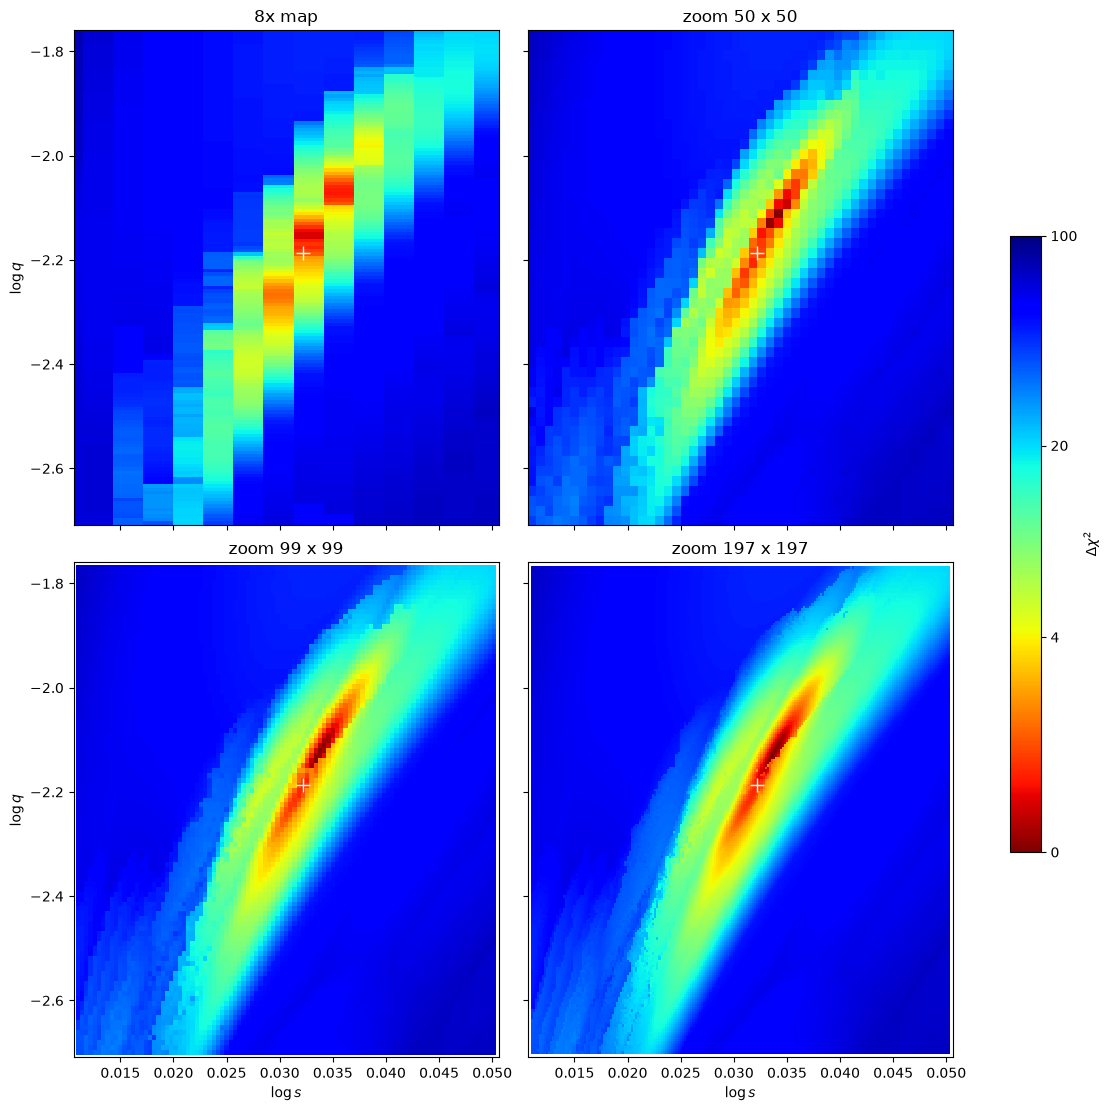

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(11, 11), constrained_layout=True, sharex=True, sharey=True)
for ax, (name, m) in zip(axs.flat, [("8x map", map8)] + ZOOMS):
    figures.plot_map(m, ax=ax, vmax=100, chi2_ref=zref, colorbar=False)
    ax.plot(best[3], best[4], "w+", ms=10)
    ax.set_title(name)
axs[0, 0].set_xlim(zlogs[0] - zls / 2, zlogs[-1] + zls / 2); axs[0, 0].set_ylim(zlogq[0] - zlq / 2, zlogq[-1] + zlq / 2)
for ax in axs[0]: ax.set_xlabel("")
for ax in axs[:, 1]: ax.set_ylabel("")
cb = fig.colorbar(axs[0, 0].images[0], ax=axs, shrink=0.6, ticks=np.log10(ticks + 1))
cb.set_ticklabels([str(t) for t in ticks]); cb.set_label(r"$\Delta\chi^2$");

The 8× map resolves the valley only across a handful of columns. In the zooms it is a single smooth, tilted ellipse:
*s* and *q* are correlated along it, a larger mass ratio going with a slightly wider separation. As in Section 8.1,
we compare each zoom with the finest at their shared points:

In [11]:
for name, z, step in [("zoom 50 x 50", zoom1, 4), ("zoom 99 x 99", zoom2, 2)]:
    c4 = zoom4["chi2"][::step, ::step]
    diff = z["chi2"] - c4
    sel = c4 - zref < 16
    print(f"{name} vs 197 x 197, Delta chi2 < 16: {sel.sum():4d} points, coarser higher by > 1 at "
          f"{100 * (diff[sel] > 1).mean():2.0f} %, by > 10 at {100 * (diff[sel] > 10).mean():.1f} %, "
          f"lower by > 1 at {100 * (diff[sel] < -1).mean():.1f} %")

zoom 50 x 50 vs 197 x 197, Delta chi2 < 16:  431 points, coarser higher by > 1 at  8 %, by > 10 at 1.6 %, lower by > 1 at 0.0 %
zoom 99 x 99 vs 197 x 197, Delta chi2 < 16: 1705 points, coarser higher by > 1 at  3 %, by > 10 at 0.0 %, lower by > 1 at 0.0 %


The 99 × 99 zoom is already within 1 of the finest one at 97 % of the points with Δχ² < 16 and never more than 10
above it, and the minimum changed by only 0.02 in the last doubling. The zoom has converged, at a total cost of 48
minutes, a fifth of the 8× map.

**The zoom found a better fit.** Its lowest point is 0.45 below the 8× minimum and 0.80 below our stored best fit,
which was fitted in all seven parameters with `lenscape.fit_full`. In a narrow, tilted valley a simplex fit creeps
along the valley floor slowly and can stop early. A full fit started from the zoom minimum (about 10 s):

In [12]:
i, j = np.unravel_index(np.nanargmin(zoom4["chi2"]), zoom4["chi2"].shape)
c_zoom, p_zoom = lenscape.fit_full(data, lenscape.fit.full_p(zoom4["pars"][i, j], zoom4["logs"][i], zoom4["logq"][j]))
for label, c, p in [("stored best fit", chi2_best, best), ("refit from the zoom", c_zoom, p_zoom)]:
    print(f"{label:20s}: chi2 = {c:.2f};  s = {10 ** p[3]:.4f}, q = {10 ** p[4] * 1e3:.2f}e-3, tE = {p[2]:.2f} d, "
          f"rho = {10 ** p[6] * 1e3:.2f}e-3")

stored best fit     : chi2 = 909.00;  s = 1.0770, q = 6.51e-3, tE = 44.71 d, rho = 1.11e-3
refit from the zoom : chi2 = 908.16;  s = 1.0808, q = 7.49e-3, tE = 43.08 d, rho = 0.98e-3


The refit lowers χ² by 0.8 and moves *q* from 6.5 to 7.5 × 10⁻³, *s* from 1.077 to 1.081 and *t*ₑ from 44.7 to 43.1 d.
Both fits lie within the 1σ errors of Han et al. (*q* = 6.97 ± 0.89 × 10⁻³, *s* = 1.0779 ± 0.0037, *t*ₑ = 43.4 ± 1.7 d):
an improvement of Δχ² < 1 moves the parameters by less than their uncertainties. The rest of this notebook keeps the
stored best fit; none of its conclusions depends on a difference of less than 1 in χ².

Along the left flank of the valley the finest zoom shows a sharp edge, from log *s* ≈ 0.02 at the bottom of the box
to ≈ 0.03 at the top, with streaks to its left. There neighbouring points end in two different families of solutions, so the map jumps from
one point to the next. The edge appears at every resolution and lies at Δχ² ≈ 12–33, outside the inner bands.
**For your own event:** when the valley is narrower than the map's step, a zoom around it is the cheapest way to find
the true minimum and the shape of the inner bands.

## 7. What the alternatives look like

We pick the lowest map point in three regions and draw its light curve next to the best fit:

* a **close** solution on the left arm (log *s* < −0.05);
* a **wide** solution on the right arm (log *s* > 0.07);
* a **low-*q*** solution in the column below log *q* = −3.

The map stores the five fitted parameters `(t0, u0, tE, alpha, log rho)` at each (*s*, *q*), and
`lenscape.fit.full_p` turns them into the seven-parameter vector.

best fit  log s = +0.032  log q = -2.186  tE =  44.7 d  alpha = 3.59  Delta chi2 =   0.3, of which the t1 point  0.0
close     log s = -0.169  log q = -2.072  tE =  22.0 d  alpha = 0.84  Delta chi2 =  35.5, of which the t1 point 34.4
wide      log s = +0.112  log q = -2.072  tE =  42.4 d  alpha = 4.08  Delta chi2 =  53.4, of which the t1 point  0.0
low q     log s = +0.016  log q = -3.033  tE =  86.3 d  alpha = 3.50  Delta chi2 =  37.6, of which the t1 point  0.0


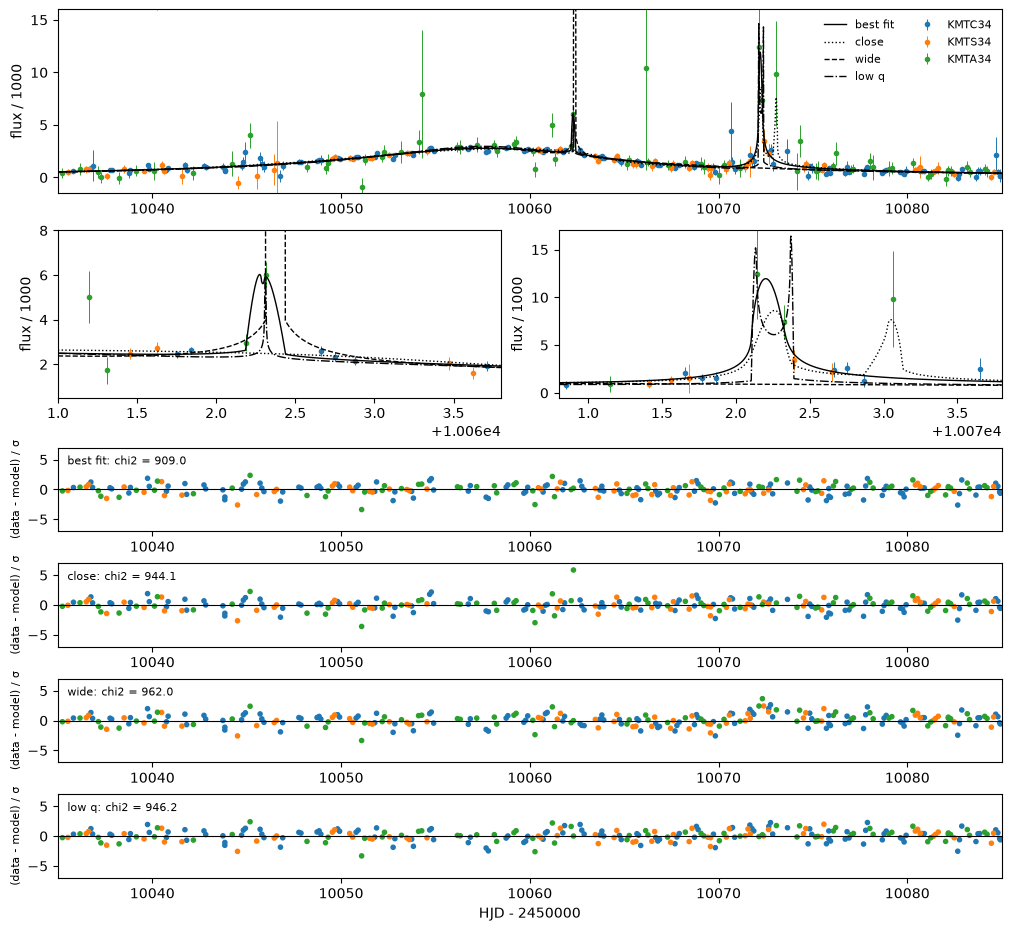

In [13]:
def lowest(m, s_range, q_range=(-9, 9)):
    si = np.where((m["logs"] > s_range[0]) & (m["logs"] < s_range[1]))[0]
    qi = np.where((m["logq"] > q_range[0]) & (m["logq"] < q_range[1]))[0]
    sub = m["chi2"][np.ix_(si, qi)]
    a, b = np.unravel_index(np.nanargmin(sub), sub.shape)
    i, j = si[a], qi[b]
    return np.array(lenscape.fit.full_p(m["pars"][i, j], m["logs"][i], m["logq"][j]))

sols = {"best fit": best, "close": lowest(map8, (-0.3, -0.05)), "wide": lowest(map8, (0.07, 0.3)),
        "low q": lowest(map8, (-0.05, 0.1), (-4, -3.0))}
k1 = np.argmin(abs(data.t - 10062.312))                  # the KMTA point at t1
for name, p in sols.items():
    r = lenscape.model.residuals(be, p, data)
    print(f"{name:9s} log s = {p[3]:+.3f}  log q = {p[4]:+.3f}  tE = {p[2]:5.1f} d  alpha = {p[5]:.2f}  "
          f"Delta chi2 = {np.sum(r ** 2) - ref:5.1f}, of which the t1 point {r[k1] ** 2:4.1f}")
plot_flux(sols);

The wide and low-*q* solutions fail at *t*₂ (Δχ² ≈ 53 and ≈ 38): the wide one misses the second anomaly altogether
and instead crosses a caustic at *t*₁ between two data points (its spikes are cut off in the plot); the low-*q* one
puts two narrow spikes where the data show one broad bump.

The close solution is a different geometry altogether: a trajectory angle about 2.7 rad from that of the best fit and
half the timescale (*t*ₑ ≈ 22 d). It fits *t*₂ and everything else as well as the best fit does, and loses only at the
KMTA point at *t*₁, which it misses by about 6σ. **Almost all of its Δχ² ≈ 36 comes from that one point.**

How unique would the solution be without it? We refit both solutions with the point removed (about 40 s):

In [14]:
keep = np.arange(len(data)) != k1
drop = lenscape.Data.from_sets({n: (data.t[keep & (data.idx == k)], data.f[keep & (data.idx == k)],
                                    data.e[keep & (data.idx == k)]) for k, n in enumerate(data.names)})
print(f"t1 point: HJD' {data.t[k1]:.3f} ({data.names[data.idx[k1]]}), {len(drop)} points left")
for label, d in [("all points", data), ("without the t1 point", drop)]:
    c_best, p_best = lenscape.fit_full(d, best)
    c_close, p_close = lenscape.fit_full(d, sols["close"])
    print(f"{label:21s}: best fit chi2 {c_best:.1f}, close chi2 {c_close:.1f}, Delta chi2 = {c_close - c_best:.1f} "
          f"(close: log s = {p_close[3]:+.3f}, log q = {p_close[4]:+.3f}, tE = {p_close[2]:.1f} d)")

t1 point: HJD' 10062.312 (KMTA34), 908 points left


all points           : best fit chi2 909.0, close chi2 944.1, Delta chi2 = 35.1 (close: log s = -0.169, log q = -2.072, tE = 22.0 d)


without the t1 point : best fit chi2 905.3, close chi2 908.1, Delta chi2 = 2.8 (close: log s = -0.169, log q = -2.075, tE = 22.0 d)


Without the *t*₁ point, the close solution is only Δχ² ≈ 3 worse than the published one. The uniqueness of the
solution, and with it *t*ₑ, rests on a single measurement 3 hours after the previous KMTA point and 8 hours before
the next KMTC point. Han et al. say so; the map lets us put a number on it. A map computed without the point would
show the close arm as a second minimum. If you run the pipeline on your own data, it is worth checking which data
points carry the Δχ² between the best fit and its strongest competitor.

## 8. Limits of the maps

### 8.1 Coarse maps miss low-χ² solutions

Every point of the 1×, 2× and 4× lattices is also a point of the 8× lattice. Comparing the values at these shared points
shows how much each doubling found that the coarser map missed:

In [15]:
for name, m, step in [("1x", map1, 8), ("2x", map2, 4), ("4x", map4, 2)]:
    c8 = map8["chi2"][::step, ::step]
    diff = m["chi2"] - c8
    for label, sel in [("Delta chi2 < 64 at 8x", c8 - ref < 64), ("all points", np.isfinite(c8))]:
        print(f"{name} vs 8x, {label:21s}: {sel.sum():5d} points, coarser map higher by > 1 at "
              f"{100 * (diff[sel] > 1).mean():3.0f} %, by > 10 at {100 * (diff[sel] > 10).mean():3.0f} %, "
              f"lower by > 1 at {100 * (diff[sel] < -1).mean():.1f} %")

1x vs 8x, Delta chi2 < 64 at 8x:   189 points, coarser map higher by > 1 at  39 %, by > 10 at  25 %, lower by > 1 at 0.0 %
1x vs 8x, all points           :  1248 points, coarser map higher by > 1 at  25 %, by > 10 at   7 %, lower by > 1 at 0.0 %
2x vs 8x, Delta chi2 < 64 at 8x:   761 points, coarser map higher by > 1 at  18 %, by > 10 at   6 %, lower by > 1 at 0.1 %
2x vs 8x, all points           :  4841 points, coarser map higher by > 1 at  12 %, by > 10 at   2 %, lower by > 1 at 0.0 %
4x vs 8x, Delta chi2 < 64 at 8x:  3017 points, coarser map higher by > 1 at   7 %, by > 10 at   2 %, lower by > 1 at 0.0 %
4x vs 8x, all points           : 19065 points, coarser map higher by > 1 at   6 %, by > 10 at   1 %, lower by > 1 at 0.0 %


In the region of the paper's bands (Δχ² < 64 at 8×), 25 % of the 1× points, 6 % of the 2× points and 2 % of the 4×
points were too high by more than 10. The maps converge much better than those of KMT-2020-BLG-0202, whose lattice
steps were twice as wide (there 63 % of the 1× and 23 % of the 2× points were too high by more than 10 against its 4×
map). Most of the remaining change is in the valley itself, which is narrower than the 1× step. Cuts across it at
three mass ratios:

1x: Delta chi2 < 16 at   4 points, log s +0.038 .. +0.038, log q -2.11 .. -1.96
2x: Delta chi2 < 16 at  18 points, log s +0.027 .. +0.038, log q -2.52 .. -1.96
4x: Delta chi2 < 16 at  70 points, log s +0.027 .. +0.044, log q -2.52 .. -1.88
8x: Delta chi2 < 16 at 351 points, log s +0.024 .. +0.044, log q -2.61 .. -1.85


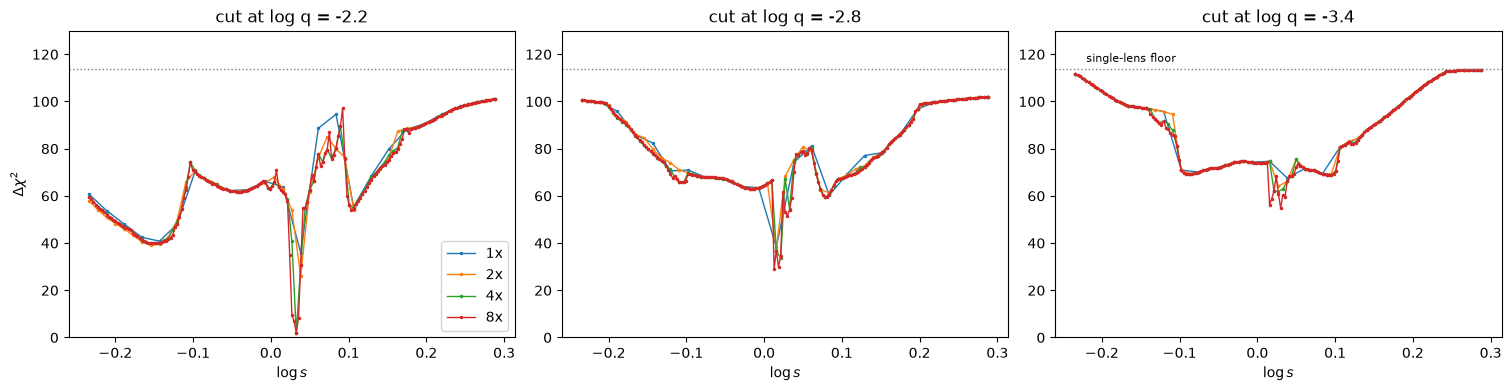

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for ax, lq in zip(axs, [-2.2, -2.8, -3.4]):
    for name, m in MAPS:
        j = np.argmin(abs(m["logq"] - lq))
        ax.plot(m["logs"], m["chi2"][:, j] - ref, ".-", ms=3, lw=1, label=name)
    ax.axhline(floor, color="grey", ls=":", lw=1)
    ax.set_ylim(0, 130); ax.set_xlabel(r"$\log s$"); ax.set_title(f"cut at log q = {lq}")
axs[0].set_ylabel(r"$\Delta\chi^2$"); axs[0].legend(); axs[2].text(-0.22, floor + 3, "single-lens floor", fontsize=8);

for name, m in MAPS:
    d = m["chi2"] - ref
    S, Q = np.meshgrid(m["logs"], m["logq"], indexing="ij")
    sel = d < 16
    print(f"{name}: Delta chi2 < 16 at {sel.sum():3d} points, log s {S[sel].min():+.3f} .. {S[sel].max():+.3f}, "
          f"log q {Q[sel].min():+.2f} .. {Q[sel].max():+.2f}")

The valley is only about 0.01 dex wide in log *s* (four 8× points at log *q* = −2.2), so a 1× column (0.023 dex) can
lie on either side of it, and the 1× map sees it only where a column happens to hit it. The region with Δχ² < 16 grows
from 4 points at 1× to 18 at 2×, 70 at 4× and 351 at 8×. Each doubling has four times as many points, so from 2× on the
area is nearly stable: it reaches log *q* = −2.52 at 2× and 4× and −2.61 at 8×. It is mainly the 1× map that
underestimates the inner bands. **For your own event,** check whether the bands you care about still change from one
doubling to the next.

### 8.2 Is the column below log *q* = −2.7 converged?

The paper's column stays in its third band (Δχ² ≤ 36) down to log *q* ≈ −3.5. Ours is below 36 from log *q* ≈ −1.5
to −2.8, at 37–40 around −3.0, and at 51–56 below −3.1. A deep search (`fit_point_heavy`: many starts, every given
warm start, several source sizes) at the column minimum of four mass ratios tests whether the map missed lower
solutions there (about 25 s):

In [17]:
cfg = dict(lenscape.config.DEFAULT, strategy="heavy",
           seed=dict(t0=best[0], u0=abs(best[1]), tE=best[2], logrho=best[6]))
col = np.where((map8["logs"] > 0) & (map8["logs"] < 0.06))[0]
for lq in [-2.9, -3.1, -3.3, -3.5]:
    j = np.argmin(abs(map8["logq"] - lq))
    i = col[np.argmin(map8["chi2"][col, j])]                  # the column minimum at this log q
    c, x = lenscape.fit.fit_point_heavy(map8["logs"][i], map8["logq"][j], data, cfg,
                                        warm=[best[[0, 1, 2, 5, 6]], map8["pars"][i, j]])
    print(f"log s = {map8['logs'][i]:.4f}, log q = {map8['logq'][j]:.3f}: map {map8['chi2'][i, j] - ref:5.1f}, "
          f"deep search {c - ref:5.1f}")

log s = 0.0157, log q = -2.898: map  37.4, deep search  37.4


log s = 0.0214, log q = -3.098: map  51.1, deep search  51.1


log s = 0.0185, log q = -3.298: map  53.8, deep search  53.8


log s = 0.0270, log q = -3.498: map  54.8, deep search  54.8


The deep searches find exactly the map's values. The difference from the paper there is in the data and error bars,
not a solution the map missed.

### 8.3 The floor region

`densify` refines only points within Δχ² < 500 of the minimum (`dchi2_cut=5.0` in units of 100). The single-lens
floor of this event is about 114, so every point is refined, unlike KMT-2020-BLG-0202. A few points still end above
the floor:

In [18]:
for name, m in MAPS:
    d = m["chi2"] - ref
    S = np.meshgrid(m["logs"], m["logq"], indexing="ij")[0]
    tE = np.abs(m["pars"][..., 2])
    above = d > (chi2_single - ref) + 1
    print(f"{name}: above the single-lens floor {above.sum():3d} points (log s <= {S[above].max():+.2f}), "
          f"at most {d.max() - (chi2_single - ref):.1f} above it;  tE at the 1000 d bound: "
          f"{100 * (tE > 990).mean():.0f} % of points")

1x: above the single-lens floor   3 points (log s <= -0.23), at most 4.6 above it;  tE at the 1000 d bound: 7 % of points
2x: above the single-lens floor   8 points (log s <= -0.22), at most 4.6 above it;  tE at the 1000 d bound: 6 % of points
4x: above the single-lens floor  24 points (log s <= -0.22), at most 4.6 above it;  tE at the 1000 d bound: 6 % of points
8x: above the single-lens floor  82 points (log s <= -0.21), at most 4.6 above it;  tE at the 1000 d bound: 5 % of points


They lie at the left edge of the lattice (log *s* ≤ −0.21) and are at most about 5 above the floor: harmless, but
still failed fits, since a binary lens can always reproduce a single lens. About 5–7 % of the points end at the
timescale bound of 1000 d, the faint-source, long-*t*ₑ branch also seen in KMT-2020-BLG-0202. They lie far from the
valleys.

### 8.4 Cost

The 4× map took 64 minutes for 19 065 points, the 8× map 222 minutes for 75 665 points (0.18 s per point, against
0.20 s at 4× and 0.31 s at 2×: denser lattices start closer to the solution). At 8× the neighbour refinement checked
90 741 points, and the outlier stage ran into its limit of 10 passes while still improving one point per pass, as at
4×. The narrower lattice keeps this event much cheaper than KMT-2020-BLG-0202 (408 minutes for 36 000 points at 4×).
The 8× map changes little against the 4× map (Section 8.1) at 3.5 times the cost. Where it does help, in the narrow
valley around the minimum, a zoom (Section 6) does better for a fifth of its cost.

## 9. Summary and using this notebook for your own event

* With the paper's lattice and all defaults, lenscape finds the published solution and the topology of the published
  map: a narrow resonant column with a close and a wide arm.
* The valley is narrower than the paper's lattice step, so the 1× map is patchy and its minimum is about 4 too high.
  Against the 8× map, the 2× and 4× maps are within 10 at 94 % and 98 % of the points with Δχ² < 64.
* A zoom on the valley (Section 6) resolves it as a smooth ellipse and finds a fit 0.8 lower in χ² than our stored
  best fit, still within the paper's errors.
* The paper's levels are lower than ours by a factor of up to about 2; deep searches confirm our values, so the
  difference lies in the data and error bars.
* The close solution (log *s* ≈ −0.17, *t*ₑ ≈ 22 d) is excluded by one KMTA point. Without it, it is only Δχ² ≈ 3
  worse than the published solution.

To run the same steps on another event:

1. Replace the CSV with your photometry, one `(t, flux, flux_err)` triple per data set, with error bars rescaled.
2. Replace `best` with a full fit (`lenscape.fit_full`).
3. Choose the axes of the first lattice.
4. Set `RECOMPUTE = True`.

**References.** Han, C., et al. 2026, arXiv:2601.13450. Yee, J. C., et al. 2012, ApJ, 755, 102.